# VAE without conditioning

Este notebook organiza el experimento del VAE no condicionado. El modelo aprende la distribucion marginal de los perfiles diarios `X` y no recibe calendario, clima, indicadores socioeconomicos ni etiquetas de provincia como entrada.

La entrada del experimento sale exclusivamente de `provincias/data/splits/`. Las muestras generadas para test provienen de la misma distribucion marginal para todos los dias.

## Setup

Importamos la funcion del experimento y las utilidades compartidas de evaluacion y graficos.

In [1]:
from pathlib import Path
from types import SimpleNamespace
import json
import sys

import pandas as pd
from IPython.display import Image, display

current_dir = Path.cwd().resolve()
if current_dir.name == "notebooks" and current_dir.parent.name == "provincias":
    provinces_root = current_dir.parent
elif current_dir.name == "provincias":
    provinces_root = current_dir
elif (current_dir / "provincias").exists():
    provinces_root = current_dir / "provincias"
else:
    raise RuntimeError("No se pudo ubicar la carpeta provincias")

src_dir = provinces_root / "src"
if str(src_dir) not in sys.path:
    sys.path.append(str(src_dir))

from model_utils import (
    list_generation_plot_paths,
    load_result_table,
    load_x_splits,
    plot_metric_by_province,
    plot_training_history,
    print_split_checks,
    validate_x_splits,
)
from vae_without_conditioning import run_vae_without_conditioning

splits_dir = provinces_root / "data" / "splits"
output_dir = provinces_root / "results" / "vae_without_conditioning"
splits_dir, output_dir

(PosixPath('/Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/data/splits'),
 PosixPath('/Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/vae_without_conditioning'))

## Datos de entrada

El VAE usa solamente los arrays `X_train`, `X_val` y `X_test`. Se verifican dimensiones y ausencia de NaNs antes de entrenar o leer resultados.

In [2]:
X = load_x_splits(splits_dir)
validate_x_splits(X)
print_split_checks(X)

X_train: shape=(1457, 528), mean=0.0000, std=1.0000, nan_count=0
X_val: shape=(366, 528), mean=0.3081, std=1.1119, nan_count=0
X_test: shape=(485, 528), mean=0.4511, std=1.1791, nan_count=0


## Entrenamiento

El bloque siguiente invoca el experimento completo. Por defecto queda apagado para evitar reentrenar al abrir el notebook; si no existen resultados en `provincias/results/vae_without_conditioning/`, cambiar `RUN_TRAINING` a `True`.

In [3]:
RUN_TRAINING = False

config = SimpleNamespace(
    splits_dir=splits_dir,
    output_dir=output_dir,
    seed=42,
    device="auto",
    latent_dim=16,
    hidden_dim=256,
    epochs=200,
    batch_size=64,
    learning_rate=1e-3,
    weight_decay=1e-5,
    beta=0.01,
    beta_warmup_epochs=30,
    patience=25,
    min_delta=1e-5,
    n_scenarios=500,
    mmd_max_samples=1000,
    plot_days=4,
)

if RUN_TRAINING:
    output_paths = run_vae_without_conditioning(config)
    display(output_paths)
else:
    print(f"Usando resultados guardados en {output_dir}")

Usando resultados guardados en /Users/victoriapersico/Desktop/Ingenieria/Tercer Año/Machine Learning/TP_final/tp_final_ml/provincias/results/vae_without_conditioning


In [4]:
required_files = [
    output_dir / "config.json",
    output_dir / "training_history.csv",
    output_dir / "reconstruction_metrics.csv",
    output_dir / "metrics_overall.csv",
    output_dir / "metrics_by_province.csv",
]
missing_files = [path for path in required_files if not path.exists()]
if missing_files:
    raise FileNotFoundError(
        "Faltan resultados guardados. Cambiar RUN_TRAINING a True y volver a ejecutar. "
        f"Archivos faltantes: {missing_files}"
    )

## Configuracion usada

La configuracion deja trazables la dimension latente, beta, warm-up de beta, paciencia de early stopping y cantidad de escenarios generados por dia.

In [5]:
with open(output_dir / "config.json", "r", encoding="utf-8") as file:
    saved_config = json.load(file)

display(pd.Series(saved_config, name="value").to_frame())

,value
batch_size,64
beta,0.01
beta_warmup_epochs,30
data_source,/Users/victoriapersico/Desktop/Ingenieria/Terc...
device,mps
epochs,200
hidden_dim,256
latent_dim,16
learning_rate,0.001
model,vae_without_conditioning


## Curvas de entrenamiento

El VAE optimiza reconstruction loss mas beta por divergencia KL. La curva total muestra el criterio usado para early stopping; las curvas separadas ayudan a detectar subajuste, sobreajuste o colapso del posterior.

,epoch,beta,train_total,train_reconstruction,train_kl,val_total,val_reconstruction,val_kl,best_epoch,best_val_loss
107,108,0.01,0.066677,0.045132,2.154527,0.140300,0.116325,2.397435,87,0.134457
108,109,0.01,0.066588,0.045049,2.153959,0.136259,0.112437,2.382200,87,0.134457
109,110,0.01,0.066078,0.044413,2.166477,0.137970,0.113455,2.451508,87,0.134457
110,111,0.01,0.066200,0.044450,2.174985,0.142208,0.118058,2.415039,87,0.134457
111,112,0.01,0.068175,0.046543,2.163172,0.140640,0.116752,2.388755,87,0.134457


,split,reconstruction_mse_scaled
0,train,0.043494
1,val,0.104020
2,test,0.152926


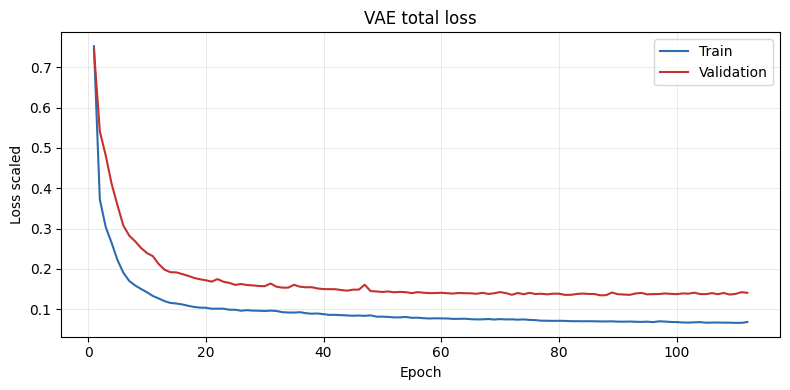

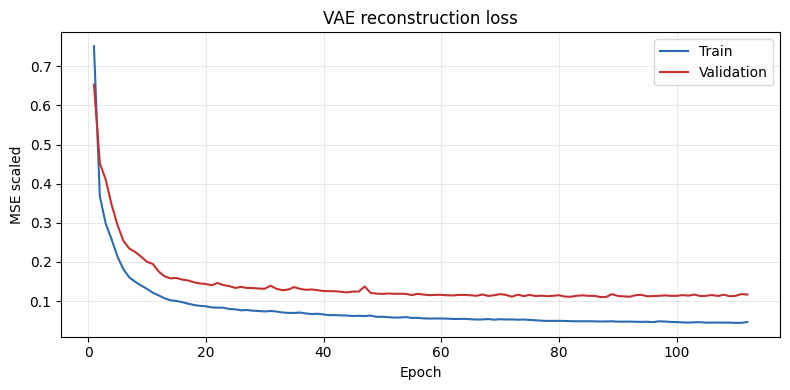

In [6]:
history = load_result_table(output_dir, "training_history.csv")
reconstruction_metrics = load_result_table(output_dir, "reconstruction_metrics.csv")

display(history.tail())
display(reconstruction_metrics)
plot_training_history(
    history,
    train_column="train_total",
    val_column="val_total",
    title="VAE total loss",
    ylabel="Loss scaled",
)
plot_training_history(
    history,
    train_column="train_reconstruction",
    val_column="val_reconstruction",
    title="VAE reconstruction loss",
    ylabel="MSE scaled",
)

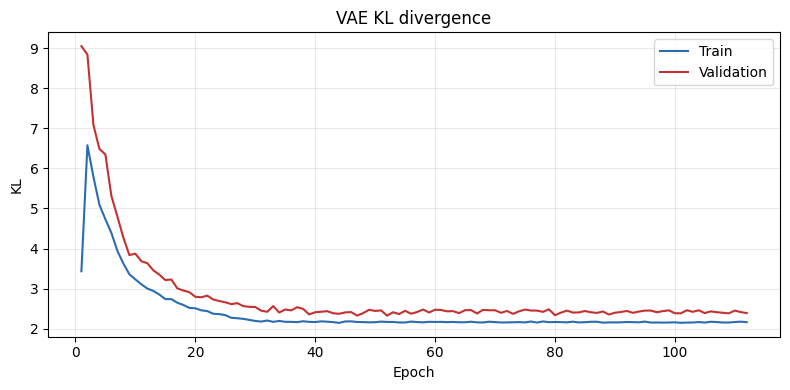

In [7]:
plot_training_history(
    history,
    train_column="train_kl",
    val_column="val_kl",
    title="VAE KL divergence",
    ylabel="KL",
)

## Evaluacion generativa

Para cada dia de test se generan 500 escenarios, aunque el modelo no esta condicionado por el dia. Las metricas se calculan en escala original MWh para que sean interpretables.

In [8]:
overall_metrics = load_result_table(output_dir, "metrics_overall.csv")
province_metrics = load_result_table(output_dir, "metrics_by_province.csv")

display(overall_metrics.T.rename(columns={0: "value"}))
display(province_metrics.sort_values("mean_profile_rmse_mwh").head())
display(province_metrics.sort_values("mean_profile_rmse_mwh", ascending=False).head())

,value
coverage_p5_p95,0.621899
sharpness_p5_p95_mwh,251.882659
mean_profile_rmse_mwh,308.222229
mmd_rbf,0.068548
n_days,485.000000
n_scenarios_per_day,500.000000


,province,coverage_p5_p95,sharpness_p5_p95_mwh,mean_profile_rmse_mwh,mmd_rbf
8,jujuy,0.657904,34.956924,19.322596,0.155658
18,santa_cruz,0.348625,25.770120,19.418249,0.426133
9,la_pampa,0.661684,33.350401,25.390993,0.071279
14,rio_negro,0.712199,55.281377,31.703211,0.072441
17,san_luis,0.692612,70.309338,35.310078,0.057067


,province,coverage_p5_p95,sharpness_p5_p95_mwh,mean_profile_rmse_mwh,mmd_rbf
0,buenos_aires,0.690550,2690.916434,1353.802490,0.059643
19,santa_fe,0.631186,518.902423,297.142334,0.086318
4,cordoba,0.606787,362.656697,239.112778,0.094217
2,chaco,0.602062,210.373655,149.188751,0.140871
5,corrientes,0.581959,161.948610,118.530243,0.143191


In [9]:
row = overall_metrics.iloc[0]
print(f"Coverage P5-P95: {row['coverage_p5_p95']:.3f}")
print(f"Sharpness promedio P5-P95: {row['sharpness_p5_p95_mwh']:.2f} MWh")
print(f"RMSE del perfil medio: {row['mean_profile_rmse_mwh']:.2f} MWh")
print(f"MMD RBF: {row['mmd_rbf']:.6f}")

Coverage P5-P95: 0.622
Sharpness promedio P5-P95: 251.88 MWh
RMSE del perfil medio: 308.22 MWh
MMD RBF: 0.068548


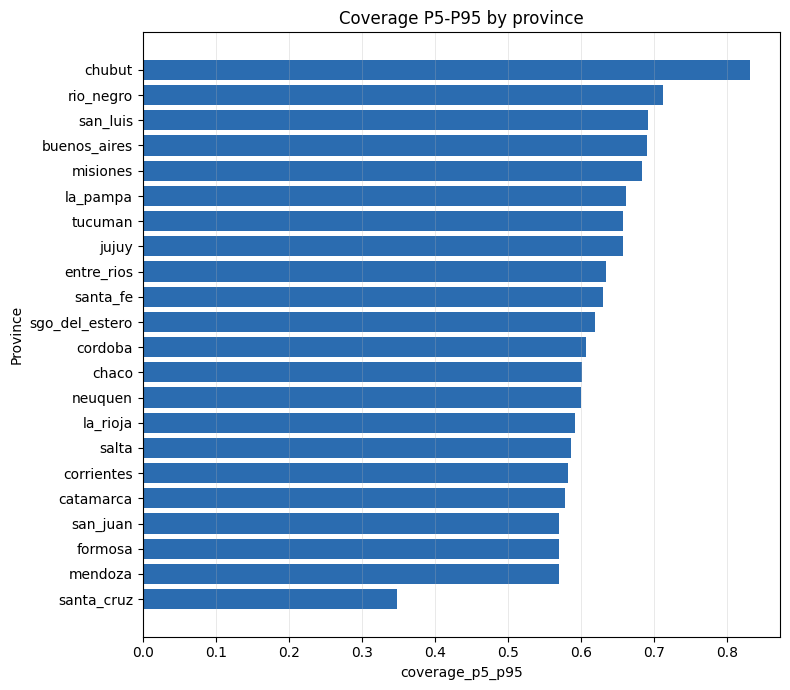

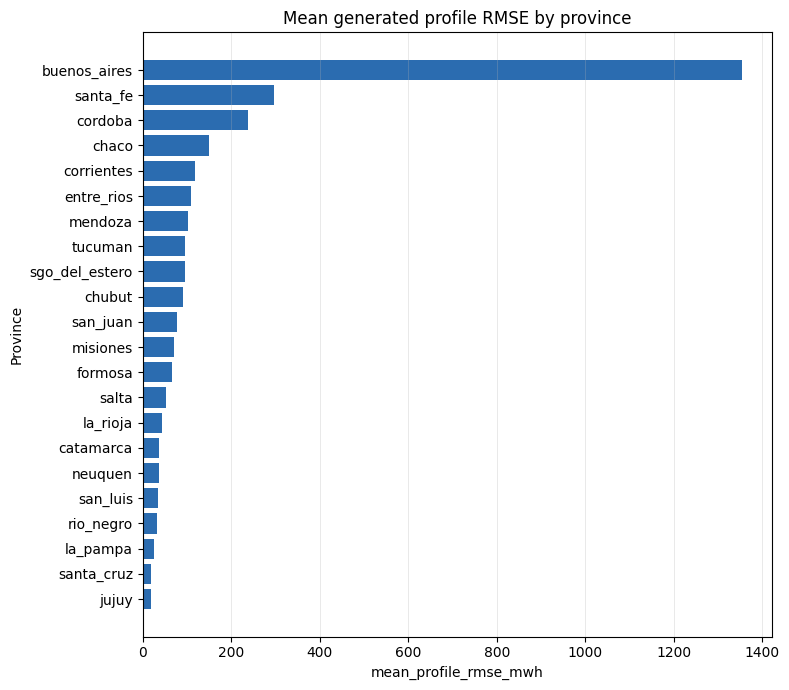

In [10]:
plot_metric_by_province(
    province_metrics,
    metric="coverage_p5_p95",
    title="Coverage P5-P95 by province",
)
plot_metric_by_province(
    province_metrics,
    metric="mean_profile_rmse_mwh",
    title="Mean generated profile RMSE by province",
)

## Perfiles reales vs generados

Estos graficos comparan perfiles reales de test contra escenarios generados desde la distribucion marginal aprendida. No deben leerse como escenarios adaptados al clima o calendario del dia.

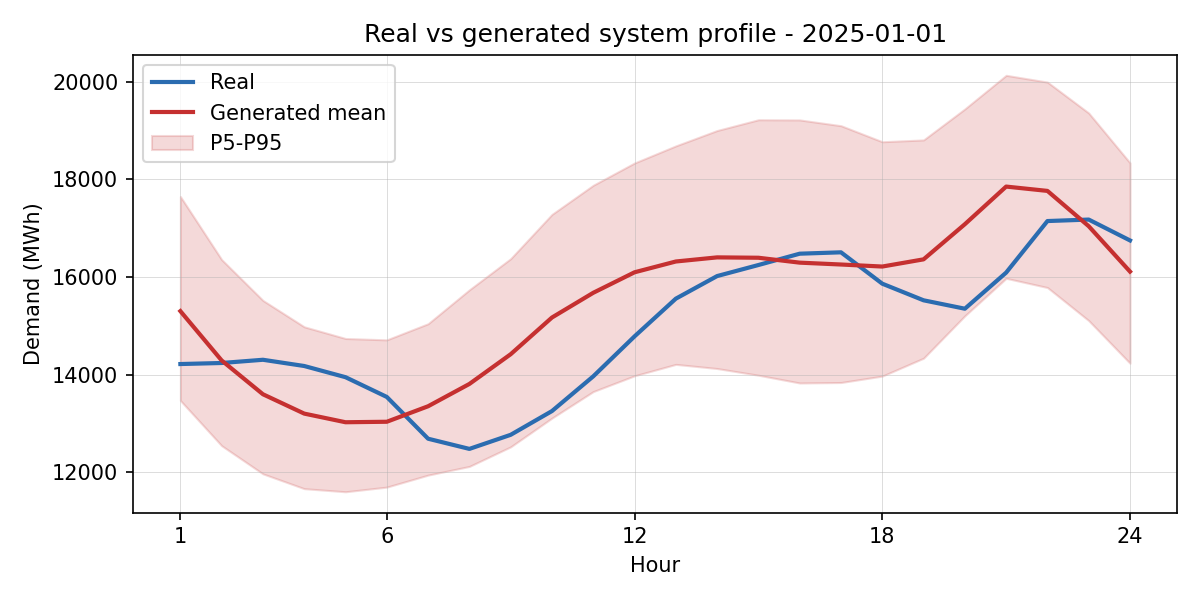

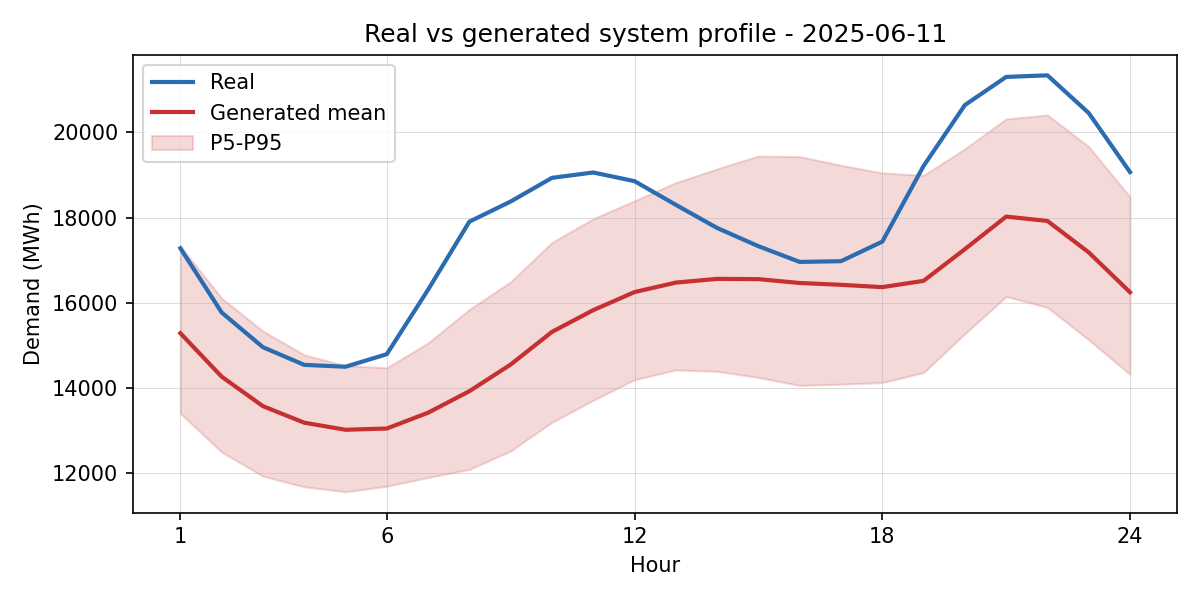

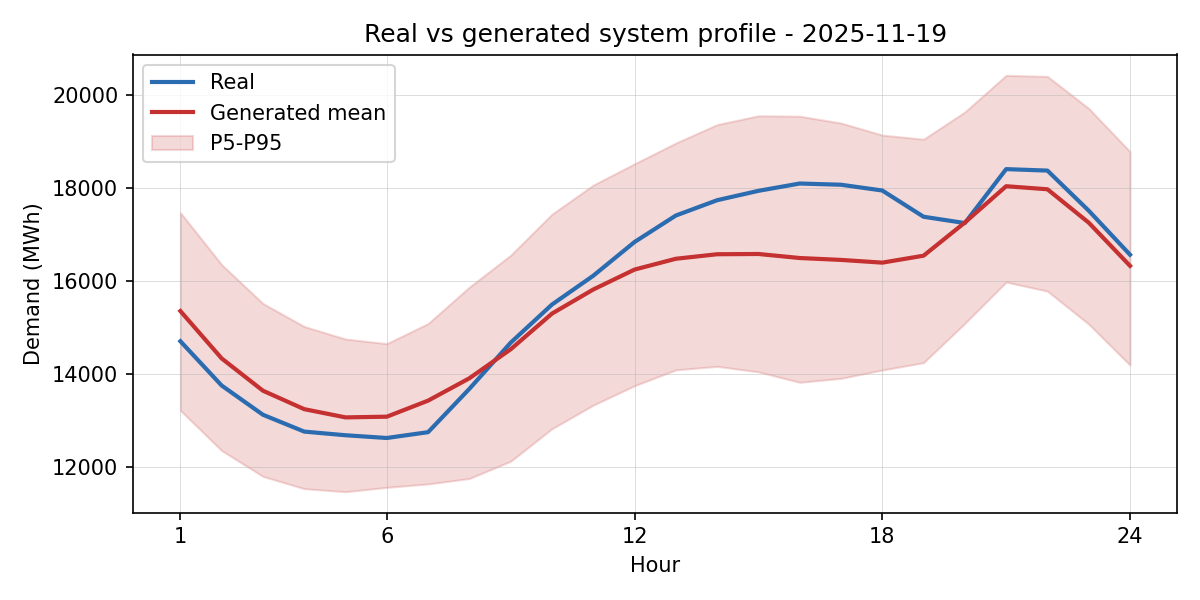

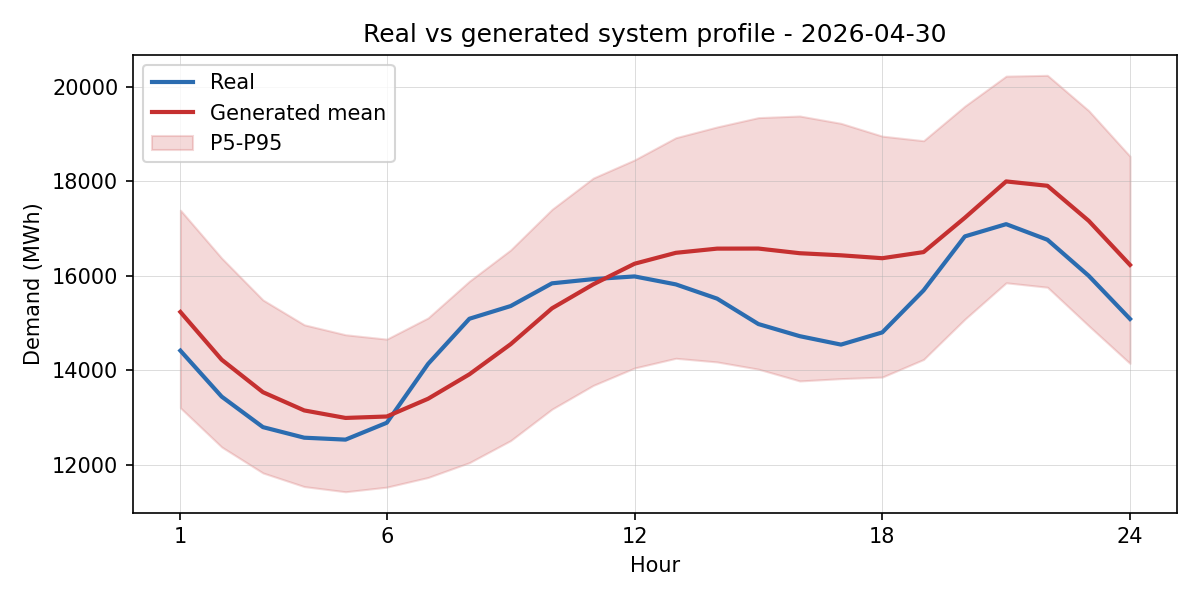

In [11]:
for plot_path in list_generation_plot_paths(output_dir, max_plots=4):
    display(Image(filename=str(plot_path)))

## Lectura del resultado

Este VAE sirve como ablation: aprende una distribucion general de perfiles diarios sin informacion contextual. Si sus metricas quedan por debajo de un modelo condicionado, esa diferencia ayuda a estimar el valor agregado de usar calendario, clima e indicadores en el CVAE. Esto se refleja en un coverage bajo y en un MMD mayor que el KDE condicional.